# FMA-full metadata exploration

FMA-full contains full-length MP3s. Each **track_id** links an audio file to a row in **tracks.csv**, which contains artist and album IDs, duration, genre tags and the published split and subset. **genres.csv** gives each genre's name and parent. The figures use the inventory and metadata tables. The track map also reads FMA's published **features.csv**.

With the FMA metadata and inventory available under **ATLAS_DATA_DIR**, select the **Music Atlas** kernel and run the cells in order. The default includes inventory tracks marked **present**. Once the audio audit supplies **manifests/tracks.parquet**, set **USE_AUDIT = True** to retain valid track IDs. The duration figures always use FMA's published metadata. [FMA data documentation](https://github.com/mdeff/fma#data)

In [1]:
import os
from ast import literal_eval
from html import escape

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.ticker import PercentFormatter

from music_atlas.settings import paths

USE_AUDIT = os.environ.get("ATLAS_FMA_USE_AUDIT") == "1"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f8fafc",
    "axes.labelcolor": "#24334a",
    "axes.edgecolor": "#d4deea",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "text.color": "#17253d",
    "xtick.color": "#3b4d65",
    "ytick.color": "#3b4d65",
    "grid.color": "#dbe4ed",
    "axes.axisbelow": True,
    "figure.dpi": 110,
})

data = paths()["data"]
metadata = data / "fma/fma_metadata"
inventory = pd.read_csv(
    data / "manifests/fma_full_inventory.csv",
    usecols=["track_id", "status", "sha1"],
    index_col="track_id",
)
assert inventory.index.is_unique and not inventory.index.hasnans
ids = inventory.index[inventory["status"].eq("present")]
if USE_AUDIT:
    audit = pd.read_parquet(
        data / "manifests/tracks.parquet", columns=["track_id", "valid", "duplicate_group"]
    ).set_index("track_id")
    assert audit.index.is_unique and not audit.index.hasnans
    assert pd.api.types.is_bool_dtype(audit["valid"]) and audit["valid"].notna().all()
    print(f"{len(ids.difference(audit.index)):,} present tracks lack an audit row.")
    ids = ids.intersection(audit.index[audit["valid"]])

assert len(ids), "The selected catalogue is empty."
fields = {
    ("artist", "id"): "artist_id",
    ("album", "id"): "album_id",
    ("set", "split"): "split",
    ("set", "subset"): "subset",
    ("track", "duration"): "duration",
    ("track", "genre_top"): "genre_top",
    ("track", "genres"): "genres",
    ("track", "genres_all"): "genres_all",
}
tracks = pd.read_csv(metadata / "tracks.csv", index_col=0, header=[0, 1], low_memory=False)
assert tracks.index.is_unique
missing_rows = len(ids.difference(tracks.index))
tracks = tracks[list(fields)].reindex(ids)
tracks.columns = list(fields.values())
for field in ["artist_id", "album_id"]:
    tracks[field] = tracks[field].where(tracks[field] > 0)

catalogue = "audited" if USE_AUDIT else "pre-audit"
print(f"{len(tracks):,} tracks ({catalogue}), {missing_rows:,} without a metadata row.")

106,574 tracks (pre-audit), 0 without a metadata row.


## FMA's genre tree

Expand a branch to see its children, then expand a child to go deeper. The first level lists every top-level **Branch** in FMA. A **Parent** is one level above a genre.

**Direct** counts tracks explicitly tagged with that genre in **genres**. **With descendants** counts tracks tagged with the genre or anything below it in the tree, using **genres_all**. A track tagged only Post-Punk counts directly under Post-Punk and toward the inclusive totals for Punk and Rock. A track with both Punk and Post-Punk tags contributes only once to the Rock total. A track can contribute to several branches. [FMA dataset paper](https://arxiv.org/html/1612.01840v3#S2.SS4)

In [2]:
genres = pd.read_csv(metadata / "genres.csv", index_col="genre_id")
labels = tracks[["genres", "genres_all"]].fillna("[]").map(literal_eval)
direct = labels["genres"].explode().dropna().reset_index(name="genre_id").drop_duplicates()
inclusive = labels["genres_all"].explode().dropna().reset_index(name="genre_id").drop_duplicates()
assert genres.index.is_unique
assert (
    direct["genre_id"].isin(genres.index).all() and inclusive["genre_id"].isin(genres.index).all()
)
assert pd.MultiIndex.from_frame(direct).isin(pd.MultiIndex.from_frame(inclusive)).all()

genres["Direct"] = direct["genre_id"].value_counts().reindex(genres.index, fill_value=0)
genres["With descendants"] = (
    inclusive["genre_id"].value_counts().reindex(genres.index, fill_value=0)
)


roots = genres[genres["parent"].eq(0)]
children = genres[genres["parent"].ne(0)].nlargest(10, "With descendants")
children_by_parent = genres.sort_values("title").groupby("parent").groups


def genre_node(genre_id):
    row = genres.loc[genre_id]
    name = escape(row["title"])
    counts = f"{row['Direct']:,} direct · {row['With descendants']:,} with descendants"
    subgenres = children_by_parent.get(genre_id, ())
    if not len(subgenres):
        return f"{name} — {counts}"
    items = "".join(f"<li>{genre_node(child)}</li>" for child in subgenres)
    summary = f"<summary><strong>{name}</strong> — {counts}</summary>"
    return f"<details>{summary}<ul>{items}</ul></details>"


tree = "".join(f"<li>{genre_node(root)}</li>" for root in roots.sort_values("title").index)
display(HTML(f"<ul>{tree}</ul>"))

root_tags = inclusive[inclusive["genre_id"].isin(roots.index)]
roots_per_track = root_tags.groupby("track_id").size().reindex(ids, fill_value=0)


def plot_genre_counts(rows, title):
    fig, ax = plt.subplots(figsize=(8, 1.5 + 0.31 * len(rows)), layout="constrained")
    rows.sort_values("With descendants").set_index("title")[
        ["Direct", "With descendants"]
    ].plot.barh(ax=ax, color=["#5352a3", "#2a9d8f"], width=0.76, title=title)
    ax.set(xlabel="Unique tracks", ylabel="")
    ax.xaxis.set_major_formatter("{x:,.0f}")
    ax.grid(axis="x")
    ax.legend(loc="lower right", facecolor="white")
    plt.show()

### Top-level genres

Each pair of bars compares explicit tags with the total that includes subgenres. A large gap shows that much of a branch's support comes from more specific tags. Tracks can contribute to more than one branch.

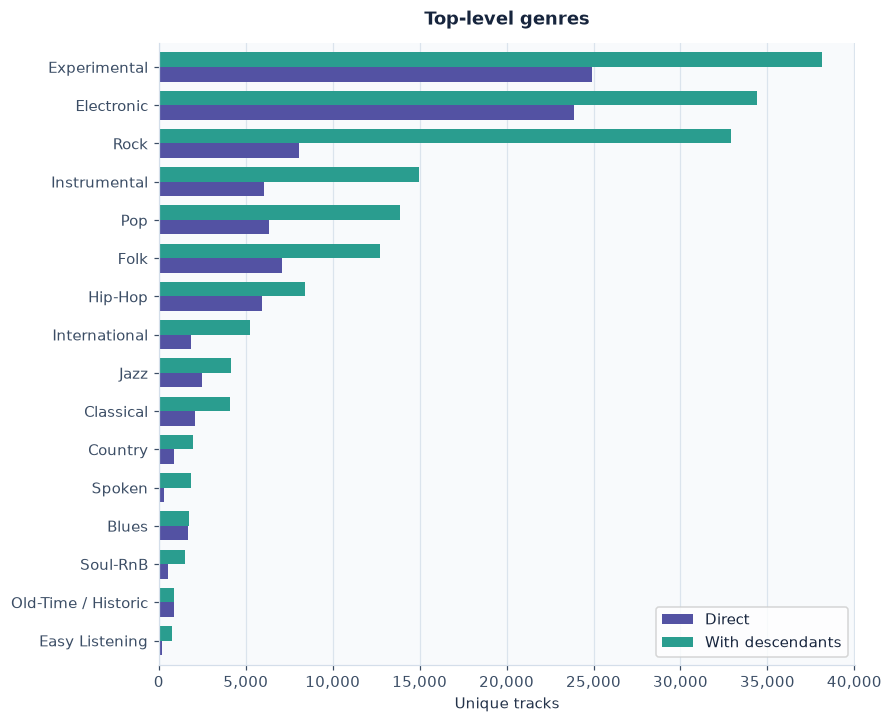

In [3]:
plot_genre_counts(roots, "Top-level genres")

### Most frequent subgenres

These are the ten genres below the top level with the largest inclusive counts. A subgenre can have descendants of its own. The same pair of bars shows how much support comes from more specific tags.

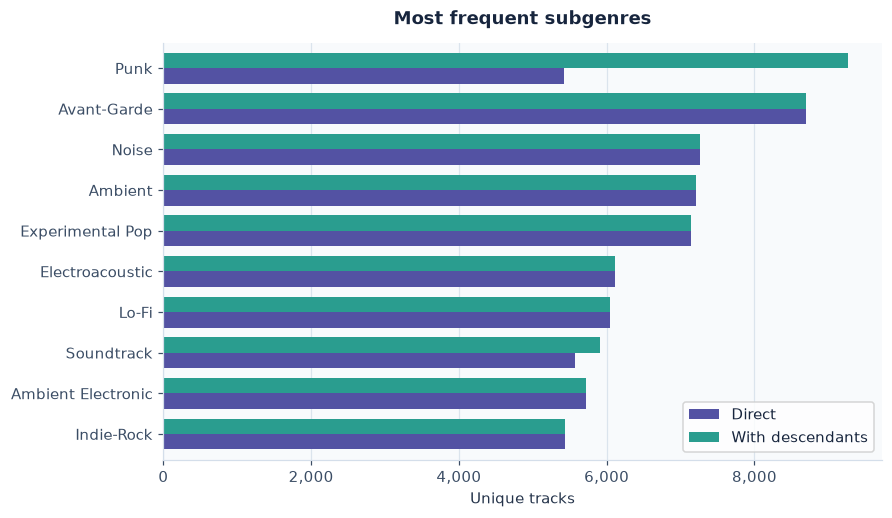

In [4]:
plot_genre_counts(children, "Most frequent subgenres")

___
## Which direct labels appear together?

Rows and columns show the ten most frequent **direct** labels. Each cell shows the percentage of tracks with **both** labels among the tracks with **at least one** of them. Suppose 60 tracks have tag A, 50 have tag B and 10 have both. There are 60 + 50 − 10 = 100 unique tracks with at least one tag. The **Jaccard overlap** is 10 / 100 = 10%.

Darker colours show greater overlap. The diagonal is blank because each label would overlap perfectly with itself. Counting explicit tags keeps parent–child relationships from automatically creating overlap. The heatmap measures shared annotations, and FMA's tags may be incomplete.

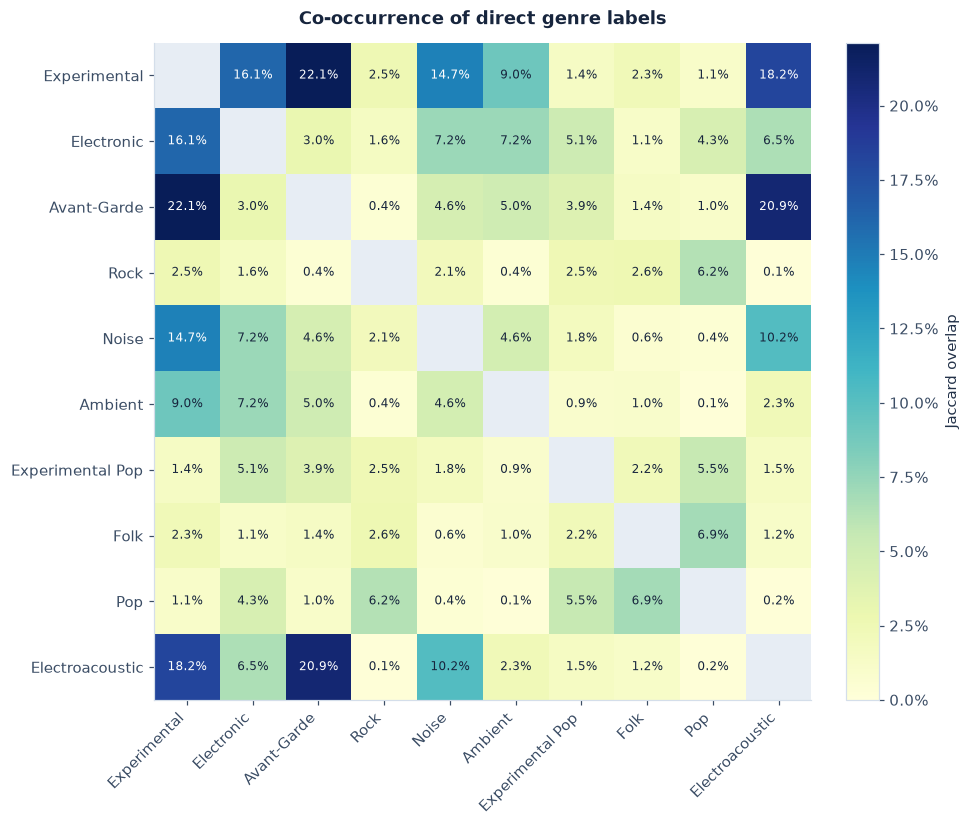

In [5]:
def label_overlap(tags, genre_ids):
    flags = pd.crosstab(tags["track_id"], tags["genre_id"]).reindex(columns=genre_ids)
    flags = flags.to_numpy(dtype=np.int64)
    shared = flags.T @ flags
    totals = shared.diagonal()
    return shared / (totals + totals[:, None] - shared)


common = genres[genres["Direct"].gt(0)].nlargest(10, "Direct").index
if len(common) >= 2:
    selected = direct[direct["genre_id"].isin(common)]
    similarity = label_overlap(selected, common)
    np.fill_diagonal(similarity, np.nan)

    fig, ax = plt.subplots(figsize=(8.8, 7.4), layout="constrained")
    cmap = plt.get_cmap("YlGnBu").with_extremes(bad="#e7edf4")
    vmax = np.nanmax(similarity) or 1
    heatmap = ax.imshow(similarity, cmap=cmap, vmin=0, vmax=vmax)
    for (row, col), value in np.ndenumerate(similarity):
        if np.isfinite(value):
            ax.text(
                col, row, f"{value:.1%}", ha="center", va="center", fontsize=8,
                color="white" if value > 0.6 * vmax else "#17253d",
            )
    ax.set_xticks(range(len(common)), genres.loc[common, "title"], rotation=45, ha="right")
    ax.set_yticks(range(len(common)), genres.loc[common, "title"])
    ax.set_title("Co-occurrence of direct genre labels")
    fig.colorbar(heatmap, ax=ax, label="Jaccard overlap", format=PercentFormatter(1))
    plt.show()
else:
    print("Co-occurrence requires at least two observed genres.")

## Track map from acoustic features

Each dot is one selected track. The coordinates come from PCA on FMA's 518 published audio features, which summarise properties such as spectral shape, timbre and pitch. Missing feature values are imputed with training medians. The imputer, standardisation and PCA are fit on the published training split. The fitted projection then places tracks from all splits on the same map. [FMA features](https://arxiv.org/html/1612.01840v3#S2.SS5)

Colour shows a track's original top-level FMA branch when it has exactly one. Tracks with several branches or with no branch tag have their own colours. In the plot cell, set **FOCUS_BRANCH** to a name such as **Jazz** and rerun that cell to highlight all tracks with that branch, including multi-label tracks. The two PCA axes retain part of the feature variation, so use the map to explore broad patterns.

The first figure zooms in on the dense part of the map. **ZOOM_TAIL** trims the view at both ends of each axis and the output reports how many dots are visible. The last figure shows the complete range with the same coordinates. For a tighter view, increase **ZOOM_TAIL** in the plot cell and rerun it.

In [6]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

features = pd.read_csv(
    metadata / "features.csv", index_col=0, header=[0, 1, 2], dtype=np.float32
)
assert features.index.is_unique
feature_values = features.reindex(ids).to_numpy(copy=True)
del features
feature_values[~np.isfinite(feature_values)] = np.nan
has_features = np.isfinite(feature_values).any(axis=1)
training = tracks["split"].eq("training").to_numpy() & has_features
assert training.sum() >= 2, "PCA requires at least two training tracks with acoustic features."

projection = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PCA(n_components=2, svd_solver="randomized", random_state=0),
)
projection.fit(feature_values[training])
xy = pd.DataFrame(
    projection.transform(feature_values[has_features]),
    index=ids[has_features],
    columns=["PC1", "PC2"],
)
del feature_values
assert np.isfinite(xy.to_numpy()).all()
variance = projection.named_steps["pca"].explained_variance_ratio_
print(
    f"{len(xy):,} of {len(ids):,} selected tracks plotted from published acoustic features. "
    f"{len(ids) - len(xy):,} have no usable feature row."
)

106,574 of 106,574 selected tracks plotted from published acoustic features. 0 have no usable feature row.


Central view: 98,338 of 106,574 tracks (92.3%).


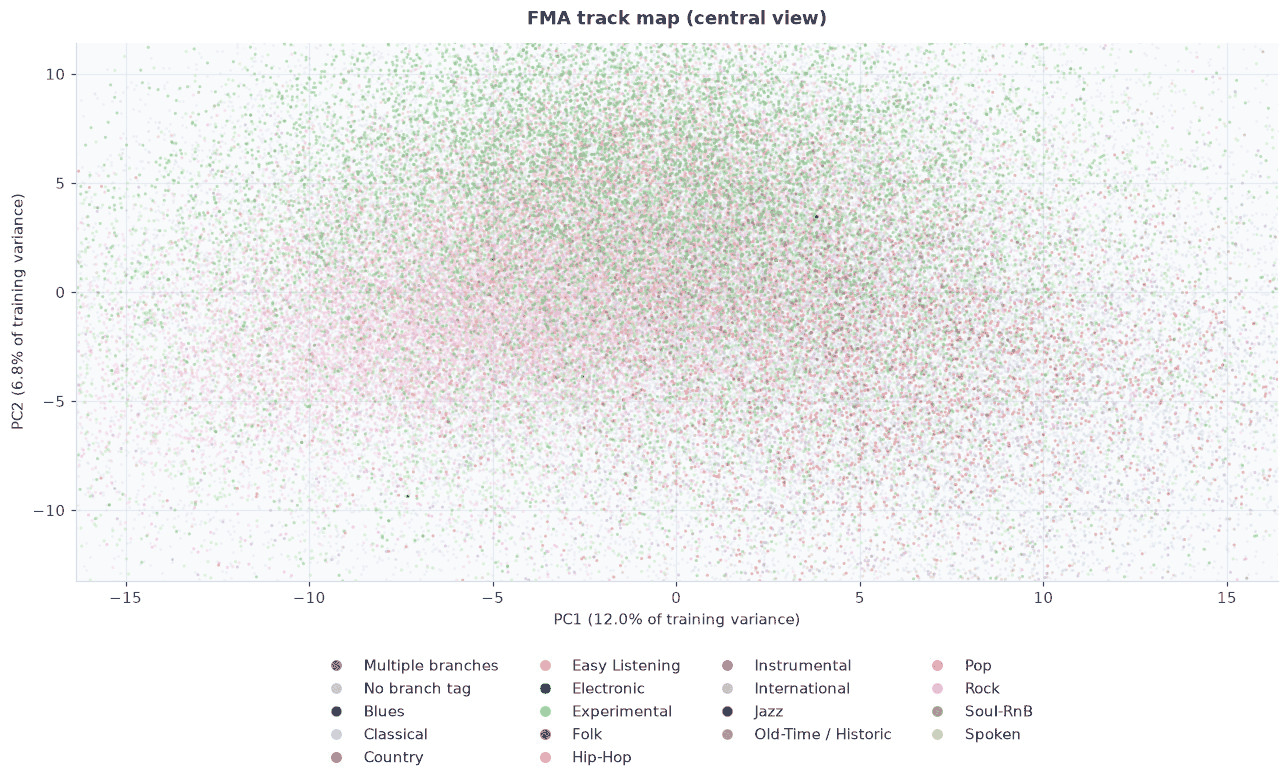

In [7]:
from io import BytesIO

from IPython.display import Image as NotebookImage
from matplotlib.lines import Line2D
from PIL import Image as PillowImage

FOCUS_BRANCH = None
ZOOM_TAIL = 0.02

branch_names = roots["title"].sort_values()
single = root_tags[root_tags["track_id"].map(roots_per_track).eq(1)]
track_colour = single.set_index("track_id")["genre_id"].map(branch_names)
track_colour = track_colour.reindex(xy.index).fillna("No branch tag")
track_colour.loc[roots_per_track.reindex(xy.index).gt(1)] = "Multiple branches"

palette = [colour for i, colour in enumerate(plt.get_cmap("tab20").colors) if i not in (14, 15)]
branch_colours = dict(zip(branch_names, palette[: len(branch_names)], strict=True))
colours = {"Multiple branches": "#64748b", "No branch tag": "#bcc5d1", **branch_colours}
if FOCUS_BRANCH is not None:
    assert FOCUS_BRANCH in branch_colours, "Choose an original FMA branch from the legend."
    genre_id = branch_names[branch_names.eq(FOCUS_BRANCH)].index[0]
    focus_ids = root_tags.loc[root_tags["genre_id"].eq(genre_id), "track_id"]
    track_colour = pd.Series(
        np.where(xy.index.isin(focus_ids), FOCUS_BRANCH, "Other tracks"), index=xy.index
    )
    colours = {"Other tracks": "#bcc5d1", FOCUS_BRANCH: branch_colours[FOCUS_BRANCH]}


assert 0 <= ZOOM_TAIL < 0.5
bounds = xy.quantile([ZOOM_TAIL, 1 - ZOOM_TAIL])
in_zoom = (xy.ge(bounds.iloc[0]) & xy.le(bounds.iloc[1])).all(axis=1)
muted_groups = {"Multiple branches", "No branch tag", "Other tracks"}
foreground = xy.loc[~track_colour.isin(muted_groups)].sample(frac=1, random_state=0)
foreground_colours = track_colour.loc[foreground.index].map(colours).tolist()
legend = [
    Line2D([], [], marker="o", linestyle="none", color=colour, markersize=6, label=group)
    for group, colour in colours.items()
    if track_colour.eq(group).any()
]
pc_labels = [f"PC{i} ({share:.1%} of training variance)" for i, share in enumerate(variance, 1)]


def show_track_figure(fig):
    with BytesIO() as rendered, BytesIO() as compact:
        fig.savefig(rendered, format="png", bbox_inches="tight")
        with PillowImage.open(rendered) as original:
            palette = original.convert("RGB").quantize(
                colors=96, dither=PillowImage.Dither.NONE
            )
            palette.save(compact, format="PNG", optimize=True)
        display(NotebookImage(data=compact.getvalue(), format="png"), include=["image/png"])
    plt.close(fig)


def plot_track_map(zoom):
    fig, ax = plt.subplots(figsize=(11.6, 7) if zoom else (9.4, 5.8), layout="constrained")
    for group in colours.keys() & muted_groups:
        points = xy.loc[track_colour.eq(group)]
        ax.scatter(
            points["PC1"], points["PC2"], s=3, color=colours[group],
            alpha=0.07, linewidths=0,
        )
    ax.scatter(
        foreground["PC1"], foreground["PC2"], s=4 if zoom else 3,
        color=foreground_colours, alpha=0.30, linewidths=0,
    )
    extent = "central view" if zoom else "full range"
    ax.set(
        xlabel=pc_labels[0], ylabel=pc_labels[1], title=f"FMA track map ({extent})",
    )
    if zoom:
        ax.set(xlim=bounds["PC1"], ylim=bounds["PC2"])
    ax.grid(alpha=0.6)
    ax.legend(
        handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.12),
        ncols=4, frameon=False,
    )
    show_track_figure(fig)


print(f"Central view: {in_zoom.sum():,} of {len(xy):,} tracks ({in_zoom.mean():.1%}).")
plot_track_map(zoom=True)

### Compare branches at the same scale

Each panel uses the central view's axes and shows all tracks carrying that branch. Tracks with several branches appear in each applicable panel. The count is the number of points inside the zoom window. Overlapping dots appear darker, which makes the dense regions easier to see. The final plot restores the full range, including the outliers.

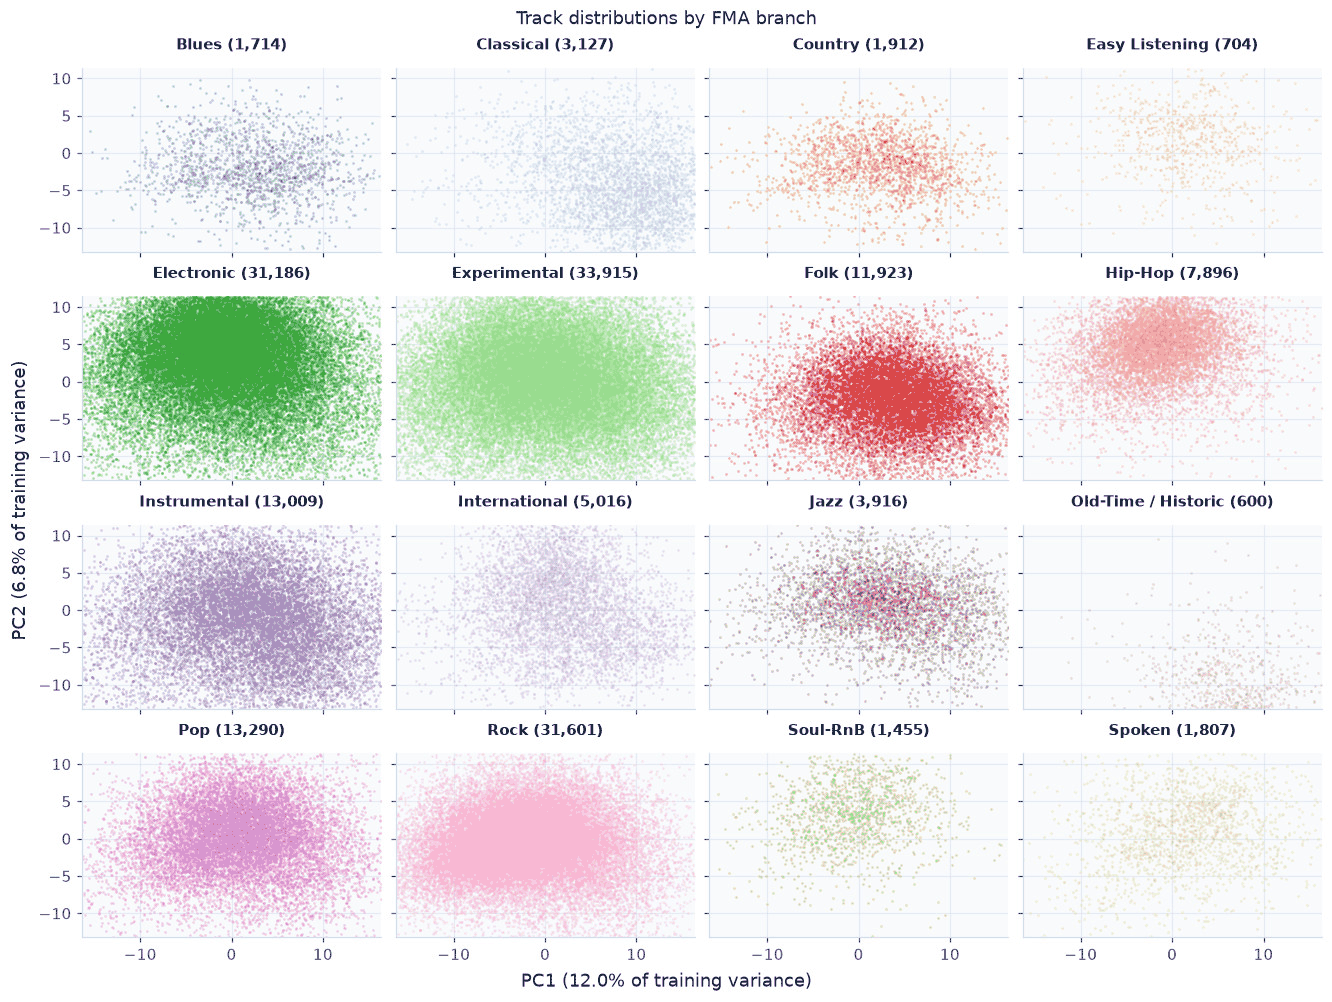

In [8]:
branch_xy = root_tags.join(xy.loc[in_zoom], on="track_id", how="inner")
fig, axes = plt.subplots(
    4, 4, sharex=True, sharey=True, figsize=(12, 9), layout="constrained"
)
for ax, (genre_id, name) in zip(axes.flat, branch_names.items(), strict=True):
    points = branch_xy[branch_xy["genre_id"].eq(genre_id)]
    ax.scatter(
        points["PC1"], points["PC2"], color=branch_colours[name],
        s=3, alpha=0.34, linewidths=0,
    )
    ax.set_title(f"{name} ({len(points):,})", fontsize=10)
    ax.set(xlim=bounds["PC1"], ylim=bounds["PC2"])
    ax.grid(alpha=0.6)
fig.suptitle("Track distributions by FMA branch")
fig.supxlabel(pc_labels[0])
fig.supylabel(pc_labels[1])
show_track_figure(fig)

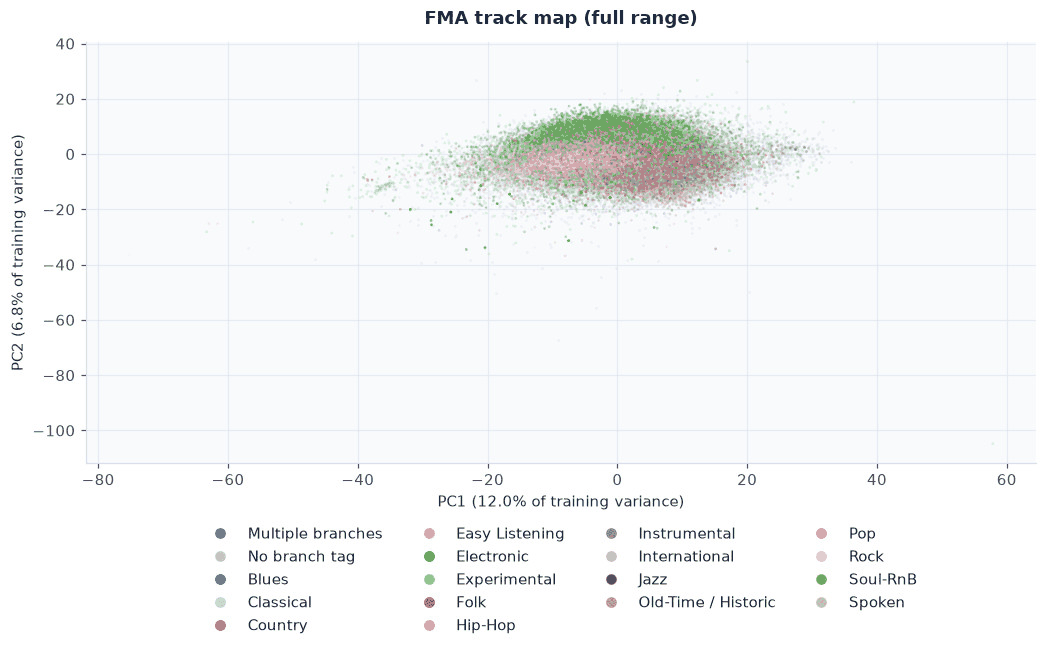

In [9]:
plot_track_map(zoom=False)

___
## Artist concentration

Artists are ranked from most to least tracks. At rank 10, the curve gives the share of the entire selected catalogue belonging to the ten largest artists. A steep rise signals concentration and can make an artist-heavy label look well supported even when it has few independent performers. The rank axis is logarithmic. Tracks with unknown artist IDs contribute to the denominator only.

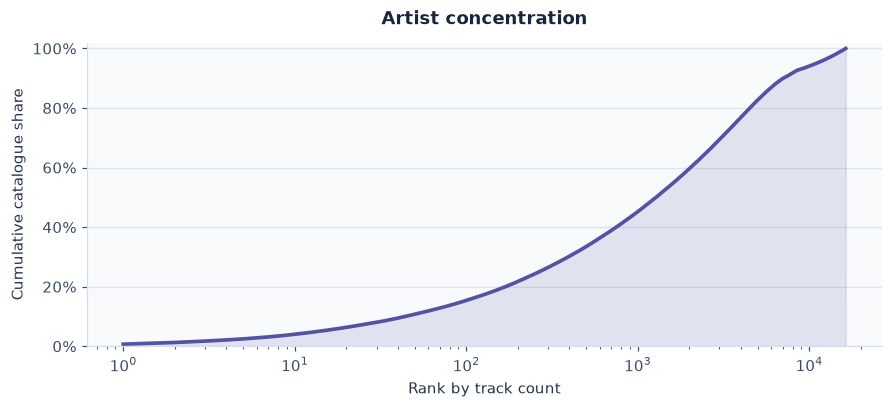

In [10]:
def plot_concentration(field, title, colour):
    counts = tracks[field].value_counts()
    ranks = np.arange(1, len(counts) + 1)
    shares = counts.cumsum().to_numpy() / len(tracks)
    fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
    ax.plot(ranks, shares, color=colour, linewidth=2.4)
    ax.fill_between(ranks, shares, color=colour, alpha=0.14)
    ax.set(
        xscale="log", xlabel="Rank by track count", ylim=(0, 1.02),
        ylabel="Cumulative catalogue share", title=title,
    )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y")
    plt.show()


plot_concentration("artist_id", "Artist concentration", "#5352a3")

___
## Album concentration

The same curve ranks albums. At rank 10, it shows how much of the full catalogue comes from the ten largest albums. A steep rise indicates that a few releases contain many tracks. Tracks with unknown album IDs contribute to the denominator only, so the curve can end below 100%.

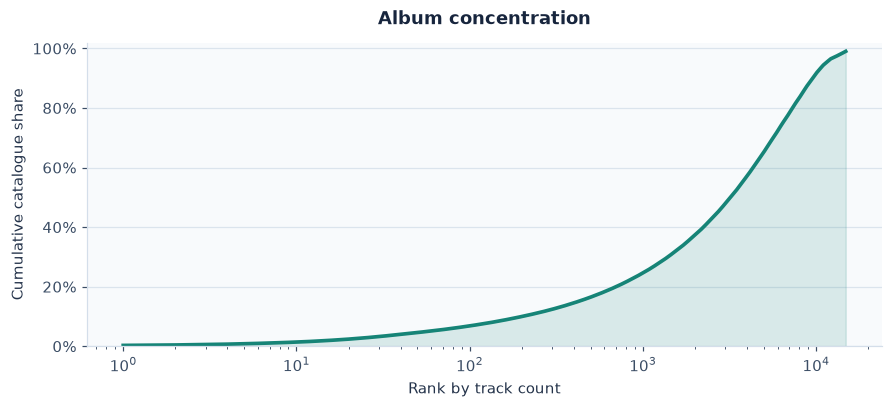

In [11]:
plot_concentration("album_id", "Album concentration", "#168477")

___
## Track durations

The histogram uses FMA's published duration in seconds. The horizontal axis is logarithmic so short and long recordings are readable on the same chart. The dashed line marks the median of positive, finite values. The coverage chart below counts missing and invalid durations.

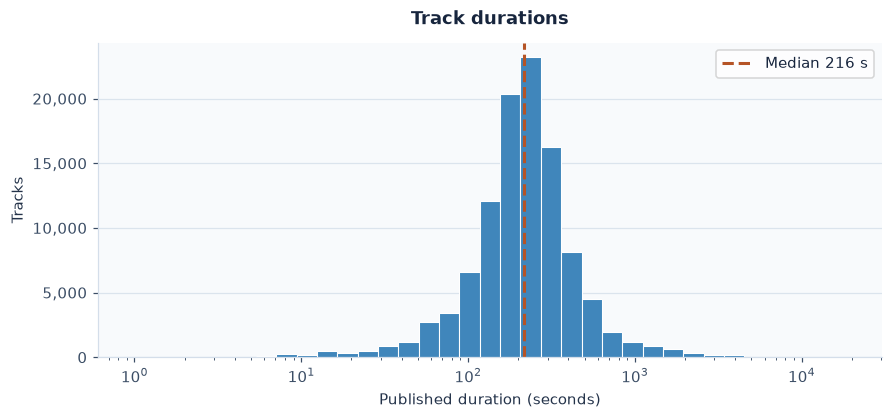

In [12]:
durations = tracks["duration"].dropna()
durations = durations[durations.gt(0) & np.isfinite(durations)]

if durations.empty:
    print("No positive, finite durations are available.")
else:
    fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
    bins = np.geomspace(durations.min() * 0.99, durations.max() * 1.01, 36)
    ax.hist(durations, bins=bins, color="#4086bb", edgecolor="white", linewidth=0.7)
    ax.axvline(
        durations.median(), color="#b55426", linestyle="--", linewidth=2,
        label=f"Median {durations.median():g} s",
    )
    ax.set(
        xscale="log", xlabel="Published duration (seconds)", ylabel="Tracks",
        title="Track durations",
    )
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.grid(axis="y")
    ax.legend(facecolor="white")
    plt.show()

___
## Annotation and metadata coverage

Bars show the percentage of **all selected tracks**, with counts printed at the end. The first three bars describe how many direct tags a track has. The fourth counts tracks spanning more than one top-level branch. Missing fields can overlap with each other and with the annotation categories. Treat absent genre tags as unknown.

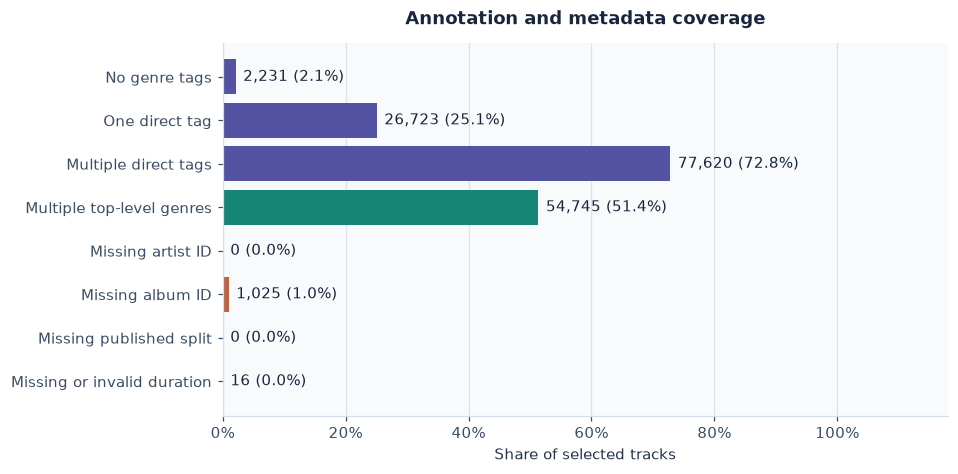

In [13]:
labels_per_track = direct.groupby("track_id").size().reindex(ids, fill_value=0)
coverage = pd.Series(
    {
        "No genre tags": labels_per_track.eq(0).sum(),
        "One direct tag": labels_per_track.eq(1).sum(),
        "Multiple direct tags": labels_per_track.gt(1).sum(),
        "Multiple top-level genres": roots_per_track.gt(1).sum(),
        "Missing artist ID": tracks["artist_id"].isna().sum(),
        "Missing album ID": tracks["album_id"].isna().sum(),
        "Missing published split": tracks["split"].isna().sum(),
        "Missing or invalid duration": len(tracks) - len(durations),
    }
)

shares = coverage / len(tracks)
fig, ax = plt.subplots(figsize=(8.6, 4.2), layout="constrained")
bars = ax.barh(
    coverage.index, shares, color=["#5352a3"] * 3 + ["#168477"] + ["#bd6447"] * 4
)
ax.bar_label(
    bars,
    labels=[f"{count:,} ({share:.1%})" for count, share in zip(coverage, shares, strict=True)],
    padding=5,
)
ax.set(xlabel="Share of selected tracks", xlim=(0, 1.18), title="Annotation and metadata coverage")
ax.set_xticks(np.linspace(0, 1, 6))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
ax.grid(axis="x")
plt.show()

___
## Rare labels and split leakage

The first table lists observed direct labels with the fewest known artists, using track count to break ties. The second shows labels with at least 20 tracks where one artist supplies the largest share. Both flag labels that may be hard to score across independent performers.

The final table counts artist IDs, album IDs and identical audio hashes seen in multiple published splits. In audited mode it also counts duplicate groups supplied by the audit. If a group spans splits, keeping its tracks together in the new split reduces leakage.

In [14]:
tagged = direct.join(tracks["artist_id"], on="track_id")
artist_counts = tagged.groupby(["genre_id", "artist_id"]).size().groupby(level=0)
support = (
    genres[["title", "Direct"]]
    .query("Direct > 0")
    .assign(
        Artists=artist_counts.size().reindex(genres.index, fill_value=0),
        Top_artist_pct=(100 * artist_counts.max() / genres["Direct"]).round(1),
    )
)
rare = support.nsmallest(5, ["Artists", "Direct"])
concentrated = support.query("Direct >= 20").nlargest(3, "Top_artist_pct").dropna()
print("Observed genres with the fewest artists")
display(rare)
print("Most concentrated genres with at least 20 direct tags")
display(concentrated)

split_groups = tracks[["artist_id", "album_id", "split"]].join(inventory["sha1"])
if USE_AUDIT:
    split_groups = split_groups.join(audit["duplicate_group"])

group_fields = {
    "artist_id": "Artists",
    "album_id": "Albums",
    "sha1": "Exact audio groups (SHA-1)",
    "duplicate_group": "Audit duplicate groups",
}
split_overlap = pd.Series({
    label: split_groups.groupby(field)["split"].nunique().gt(1).sum()
    for field, label in group_fields.items()
    if field in split_groups
})
display(split_overlap.rename("Groups spanning published splits").to_frame())

Observed genres with the fewest artists


,title,Direct,Artists,Top_artist_pct
genre_id,,,,
377,Deep Funk,1,1,100.0
173,N. Indian Traditional,4,2,75.0
374,Banter,9,2,55.6
493,Western Swing,4,3,50.0
808,Salsa,12,3,58.3


Most concentrated genres with at least 20 direct tags


,title,Direct,Artists,Top_artist_pct
genre_id,,,,
189,Talk Radio,26,5,84.6
65,Radio,166,8,83.1
176,Pacific,23,4,73.9


,Groups spanning published splits
Artists,0
Albums,670
Exact audio groups (SHA-1),11


## Class balance and the effect of duration filters

**FMA-full** can have several branches per track. The first table compares support in the current selection using FMA's own **genre_top** for Small and Medium and the original multi-label branches for Full. **Artists** counts distinct known artists in the Full branch.

The second table shows the percentage of tracks each example cutoff would remove from each branch. Ten seconds matches one analysis window. Ten minutes is an illustrative long-track cutoff. The percentages use published durations and show what these rules would change, with the catalogue kept intact. [FMA dataset paper](https://arxiv.org/html/1612.01840v3#S2.SS6)

In [15]:
short = durations[durations.lt(10)].index
long = durations[durations.gt(600)].index
branch_tracks = root_tags.join(tracks["artist_id"], on="track_id").assign(
    short=lambda rows: rows["track_id"].isin(short),
    long=lambda rows: rows["track_id"].isin(long),
)
branch_stats = branch_tracks.groupby("genre_id").agg(
    Tracks=("track_id", "size"), Artists=("artist_id", "nunique"),
    Short=("short", "sum"), Long=("long", "sum"),
)
branch_stats = branch_stats.reindex(roots.index, fill_value=0)
branch_stats = branch_stats.sort_values("Tracks", ascending=False)
branch_stats.index = pd.Index(genres.loc[branch_stats.index, "title"], name="FMA branch")
small = tracks.loc[tracks["subset"].eq("small"), "genre_top"].value_counts()
medium = tracks.loc[tracks["subset"].isin(["small", "medium"]), "genre_top"].value_counts()
balance = branch_stats[["Tracks", "Artists"]].rename(columns={"Tracks": "Full tracks"})
balance["Small tracks"] = small.reindex(balance.index, fill_value=0)
balance["Medium tracks"] = medium.reindex(balance.index, fill_value=0)
display(balance)
display(
    branch_stats[["Short", "Long"]].div(branch_stats["Tracks"], axis=0).mul(100).round(1)
    .rename(columns={"Short": "Under 10 s (%)", "Long": "Over 10 min (%)"})
)

,Full tracks,Artists,Small tracks,Medium tracks
FMA branch,,,,
Experimental,38154,6949,1000,2251
Electronic,34413,6135,1000,6314
Rock,32923,4581,1000,7103
Instrumental,14938,2286,1000,1350
Pop,13845,2036,1000,1186
Folk,12706,1517,1000,1519
Hip-Hop,8389,999,1000,2201
International,5271,1039,1000,1018
Jazz,4126,711,0,384


,Under 10 s (%),Over 10 min (%)
FMA branch,,
Experimental,0.3,10.1
Electronic,0.8,4.2
Rock,0.2,3.2
Instrumental,0.1,7.2
Pop,0.5,1.5
Folk,0.3,3.4
Hip-Hop,0.9,0.7
International,0.1,4.2
Jazz,0.1,12.9


## What to keep, audit and report

Use these checks when turning the catalogue into training and evaluation data. The figures above describe the selected track IDs. The recommendations below explain where a filter or split choice would change the experiment.

In [16]:
observed = branch_stats[branch_stats["Tracks"].gt(0)]
branch_range = "The selection has no observed branches."
if not observed.empty:
    largest = observed.iloc[0]
    smallest = observed.iloc[-1]
    branch_range = (
        f"Full branch support ranges from {smallest['Tracks']:,} ({smallest.name}) to "
        f"{largest['Tracks']:,} ({largest.name})."
    )
no_tags = coverage["No genre tags"]
no_artist = coverage["Missing artist ID"]
no_album = coverage["Missing album ID"]
bad_duration = coverage["Missing or invalid duration"]
multi_root = roots_per_track.gt(1).sum()

findings = [
    f"**Choose the published target.** {multi_root:,} tracks span several branches. "
    f"{branch_range} Use FMA-small for a balanced single-label "
    "baseline, FMA-medium for a wider single-label benchmark, or FMA-full for multi-label "
    "work. Report tracks and distinct artists per class and per split. Compare macro-F1 "
    "and per-class scores alongside overall metrics. Apply any reweighting to training only.",
    f"**Filter by task and audio quality.** {no_tags:,} tracks lack genre tags, {no_artist:,} "
    f"lack an artist ID, and {no_album:,} lack an album ID. Use labelled tracks for supervised "
    "genre scoring and keep usable unlabelled audio for exploration. Keep tracks with missing "
    "album IDs. Resolve missing artist IDs before using those tracks in an artist-disjoint "
    "evaluation. Treat absent tags as unknown and record audio exclusions by track ID.",
    f"**Check duration before setting cutoffs.** {bad_duration:,} published durations are missing "
    f"or invalid. A lower cutoff of 10 s would remove {len(short):,} tracks "
    f"({len(short) / len(tracks):.1%}), and an upper cutoff of 10 min would remove {len(long):,} "
    f"({len(long) / len(tracks):.1%}). Check the decoded duration and the per-branch impact "
    "before excluding tracks. The existing loader pads a short usable window and samples a "
    "fixed number of windows from long tracks. Start with that baseline and exclude unusable "
    "audio as determined by the audit.",
    f"**Keep related tracks together.** The published splits share {split_overlap['Artists']:,} "
    f"artist IDs, {split_overlap['Albums']:,} album IDs and "
    f"{split_overlap['Exact audio groups (SHA-1)']:,} identical-audio groups. Keep each artist, "
    "confirmed duplicate group and fragments of a recording in a single partition. "
    "Check album overlap and retain a versioned split manifest before comparing models.",
]
if not concentrated.empty:
    top = concentrated.iloc[0]
    findings[0] += f" One artist supplies {top['Top_artist_pct']:g}% of {top['title']} tags."
if USE_AUDIT:
    findings[-1] += f" {split_overlap['Audit duplicate groups']:,} audit groups span splits."
display(Markdown("\n\n".join(findings)))

**Choose the published target.** 54,745 tracks span several branches. Full branch support ranges from 730 (Easy Listening) to 38,154 (Experimental). Use FMA-small for a balanced single-label baseline, FMA-medium for a wider single-label benchmark, or FMA-full for multi-label work. Report tracks and distinct artists per class and per split. Compare macro-F1 and per-class scores alongside overall metrics. Apply any reweighting to training only. One artist supplies 84.6% of Talk Radio tags.

**Filter by task and audio quality.** 2,231 tracks lack genre tags, 0 lack an artist ID, and 1,025 lack an album ID. Use labelled tracks for supervised genre scoring and keep usable unlabelled audio for exploration. Keep tracks with missing album IDs. Resolve missing artist IDs before using those tracks in an artist-disjoint evaluation. Treat absent tags as unknown and record audio exclusions by track ID.

**Check duration before setting cutoffs.** 16 published durations are missing or invalid. A lower cutoff of 10 s would remove 512 tracks (0.5%), and an upper cutoff of 10 min would remove 5,938 (5.6%). Check the decoded duration and the per-branch impact before excluding tracks. The existing loader pads a short usable window and samples a fixed number of windows from long tracks. Start with that baseline and exclude unusable audio as determined by the audit.

**Keep related tracks together.** The published splits share 0 artist IDs, 670 album IDs and 11 identical-audio groups. Keep each artist, confirmed duplicate group and fragments of a recording in a single partition. Check album overlap and retain a versioned split manifest before comparing models.